# Практическая работа №1. Основные методы OpenCV. Часть №1

# Тема №1. Чтение, запись и отображение

## Задание 1:  
Напишите процедуру, которая:

- Считывает цветное изображение в режиме `cv2.IMREAD_COLOR`.
- Преобразует его в оттенки серого с использованием `cv2.cvtColor()`.
- Сохраняет полученное черно-белое изображение на диск.
- Отображает оба изображения (оригинальное цветное и преобразованное черно-белое).

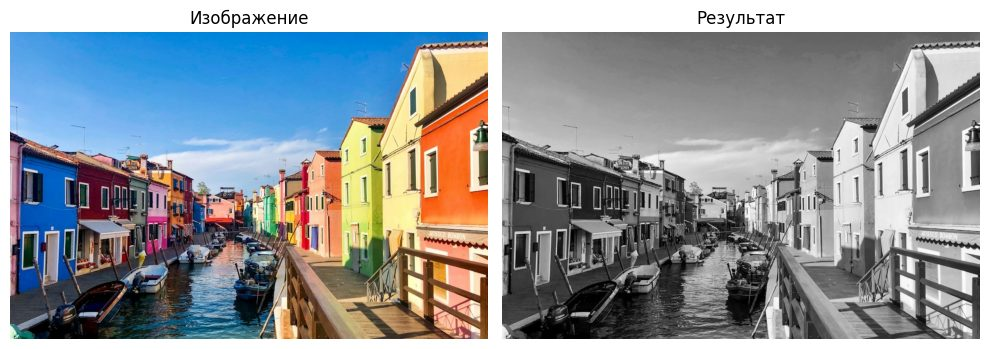

In [1]:
from pathlib import Path
from urllib.request import Request, urlopen
import tempfile
import cv2
import numpy as np
import matplotlib.pyplot as plt

workdir = tempfile.TemporaryDirectory()
files = Path(workdir.name)
url = 'https://images.unsplash.com/photo-1596449971485-15d710844a57?auto=format&fit=max&w=900&q=90'
request = Request(url, headers={'User-Agent': 'ImageProcessingCourse/1.0'})
with urlopen(request, timeout=30) as response:
    buffer = np.frombuffer(response.read(), dtype=np.uint8)
cv2.imwrite(str(files / 'image1.jpg'), cv2.imdecode(buffer, cv2.IMREAD_COLOR))
image1 = cv2.imread(str(files / 'image1.jpg'), cv2.IMREAD_COLOR)
gray = cv2.cvtColor(image1, cv2.COLOR_BGR2GRAY)
cv2.imwrite(str(files / 'gray.png'), gray)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(cv2.cvtColor(image1, cv2.COLOR_BGR2RGB))
axes[1].imshow(gray, cmap='gray', vmin=0, vmax=255)
for ax, title in zip(axes, ['Изображение', 'Результат']):
    ax.set_title(title)
    ax.axis('off')
fig.tight_layout()
plt.show()
plt.close(fig)

## Задание 2:  
Используя режим `cv2.IMREAD_UNCHANGED`, загрузите изображение с альфа-каналом (например, PNG с прозрачностью). Затем:

- Разделите изображение на каналы (B, G, R, A).
- Создайте новое изображение, где прозрачность (альфа-канал) инвертирована (т.е. прозрачные области становятся непрозрачными и наоборот).
- Сохраните и отобразите полученное изображение.

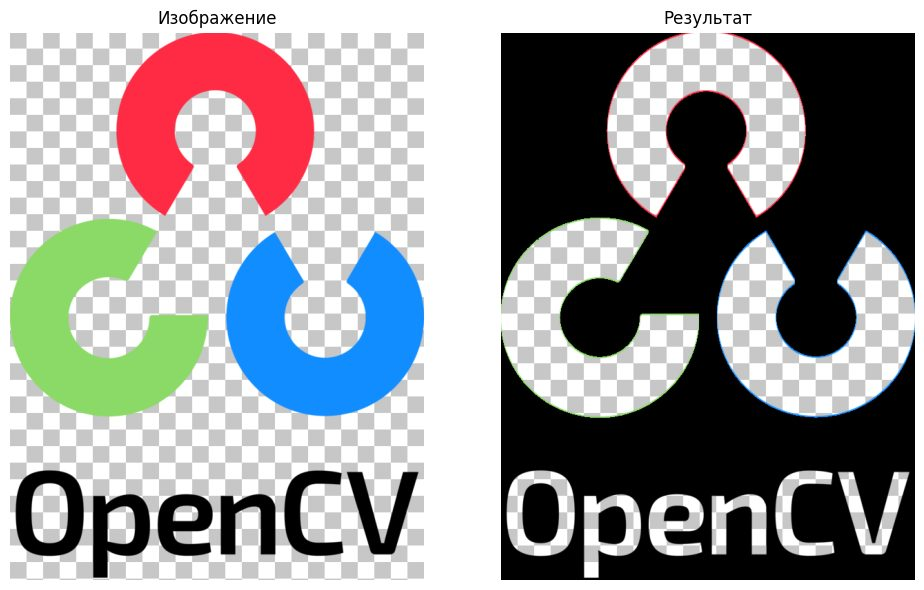

In [2]:
url = 'https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/opencv-logo.png'
request = Request(url, headers={'User-Agent': 'ImageProcessingCourse/1.0'})
with urlopen(request, timeout=30) as response:
    buffer = np.frombuffer(response.read(), dtype=np.uint8)
png = cv2.imdecode(buffer, cv2.IMREAD_UNCHANGED)
cv2.imwrite(str(files / 'alpha.png'), png)

image = cv2.imread(str(files / 'alpha.png'), cv2.IMREAD_UNCHANGED)
b, g, r, alpha = cv2.split(image)
result = cv2.merge((b, g, r, 255 - alpha))
cv2.imwrite(str(files / 'alpha_result.png'), result)

yy, xx = np.indices(image.shape[:2])
background = np.where((xx // 24 + yy // 24) % 2 == 0, 0.78, 1.0)
fig, axes = plt.subplots(1, 2, figsize=(10, 6))
for ax, title, picture in zip(axes, ['Изображение', 'Результат'], [image, result]):
    ax.imshow(background, cmap='gray', vmin=0, vmax=1)
    ax.imshow(cv2.cvtColor(picture, cv2.COLOR_BGRA2RGBA))
    ax.set_title(title)
    ax.axis('off')
fig.tight_layout()
plt.show()
plt.close(fig)

# Тема №2. Работа с цветовыми палитрами

## Задание 3:  
Напишите процедуру, которая:

- Считывает цветное изображение.
- Преобразует его из цветового пространства BGR в HSV с помощью `cv2.cvtColor()`.
- Увеличивает насыщенность (канал S) в 1.5 раза, не превышая максимального значения.
- Преобразует изображение обратно в цветовое пространство BGR.
- Отображает оригинальное и полученное изображения рядом для сравнения.

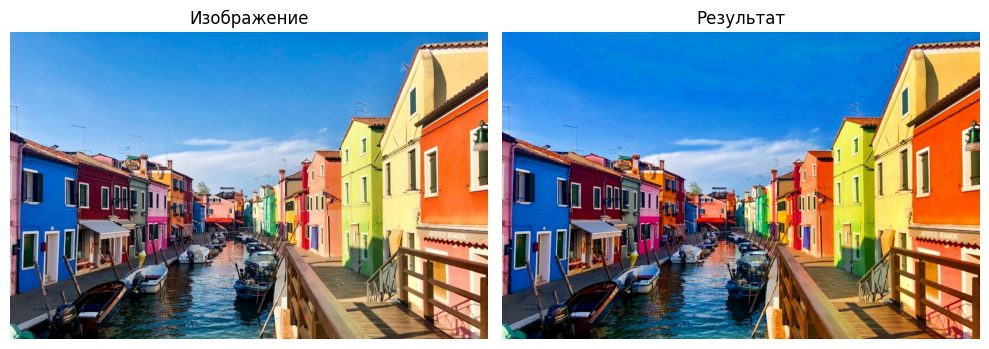

In [3]:
image = cv2.imread(str(files / 'image1.jpg'), cv2.IMREAD_COLOR)
h, s, v = cv2.split(cv2.cvtColor(image, cv2.COLOR_BGR2HSV))
s = np.clip(s.astype(np.float32) * 1.5, 0, 255).astype(np.uint8)
result = cv2.cvtColor(cv2.merge((h, s, v)), cv2.COLOR_HSV2BGR)

fig, axes = plt.subplots(1, 2, figsize=(10, 5), squeeze=False)
for ax, (title, image) in zip(axes.flat, [('Изображение', image),
        ('Результат', result)]):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis('off')
for ax in list(axes.flat)[2:]:
    ax.axis('off')
fig.tight_layout()
plt.show()
plt.close(fig)

## Задание 4:  
Напишите процедуру, которая:

- Считывает изображение и Преобразует его в цветовое пространство YCrCb.
- Применяет размытие к компоненте яркости Y (при помощи фильтра, см. материал предыдущих занятий).
- Снова Преобразует изображение в цветовое пространство BGR.
- Отображает исходное и размытое изображения.

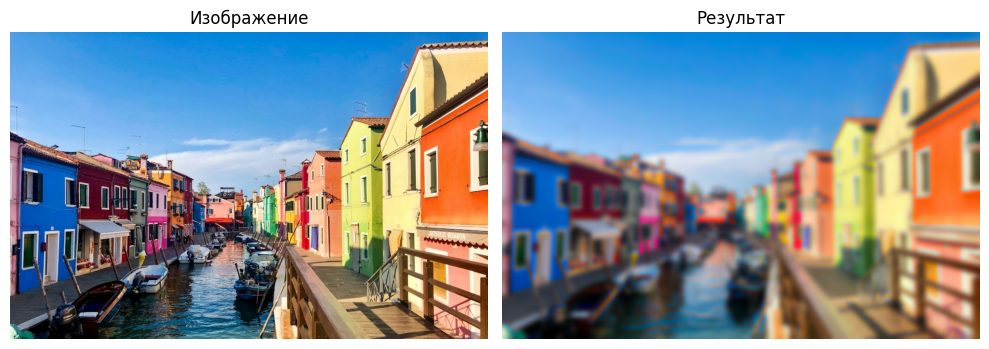

In [4]:
image = cv2.imread(str(files / 'image1.jpg'), cv2.IMREAD_COLOR)
y, cr, cb = cv2.split(cv2.cvtColor(image, cv2.COLOR_BGR2YCrCb))
y = cv2.GaussianBlur(y, (31, 31), 0)
result = cv2.cvtColor(cv2.merge((y, cr, cb)), cv2.COLOR_YCrCb2BGR)

fig, axes = plt.subplots(1, 2, figsize=(10, 5), squeeze=False)
for ax, (title, image) in zip(axes.flat, [('Изображение', image),
        ('Результат', result)]):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis('off')
for ax in list(axes.flat)[2:]:
    ax.axis('off')
fig.tight_layout()
plt.show()
plt.close(fig)

# Тема №3. Слияние и усиление

## Задание 5:  
Создайте процедуру, которая:

- Считывает два изображения одинакового размера (можно подкорректировать с помощью метода `.resize()`).
- Выполняет побитовое ИЛИ (OR) над соответствующими пикселями двух изображений.
- Сохраняет и отображает результат операции.

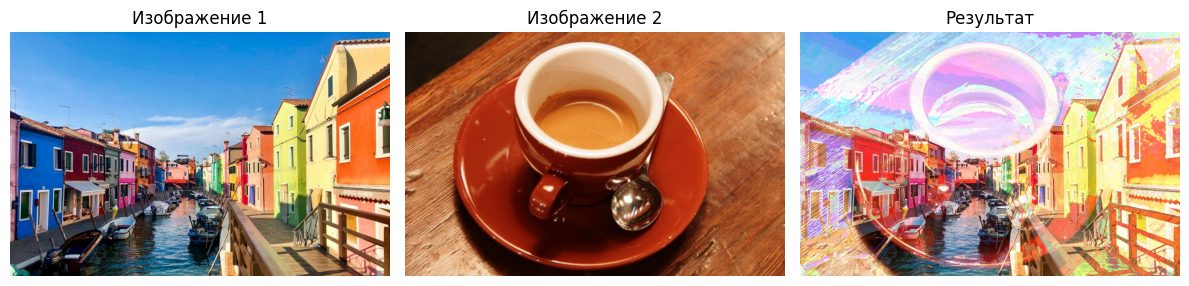

In [5]:
from skimage import data

cv2.imwrite(str(files / 'image2.jpg'), cv2.cvtColor(data.coffee(), cv2.COLOR_RGB2BGR))
image1 = cv2.imread(str(files / 'image1.jpg'))
image2 = cv2.imread(str(files / 'image2.jpg'))
image2 = cv2.resize(image2, (image1.shape[1], image1.shape[0]))
result = cv2.bitwise_or(image1, image2)
cv2.imwrite(str(files / 'or_result.png'), result)

fig, axes = plt.subplots(1, 3, figsize=(12, 5), squeeze=False)
for ax, (title, image) in zip(axes.flat, [('Изображение 1', image1),
        ('Изображение 2', image2),
        ('Результат', result)]):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis('off')
for ax in list(axes.flat)[3:]:
    ax.axis('off')
fig.tight_layout()
plt.show()
plt.close(fig)

## Задание 6:  
Реализуйте следующий алгоритм:

- Считайте цветное изображение и разделите его на три канала с использованием `.split()`.
- Примените к каждому каналу разный коэффициент гамма-коррекции (например, для R – 0.5, G – 1.0, B – 1.5).
- Объедините каналы обратно с помощью `.merge()`.
- Отобразите исходное и обработанное изображения.

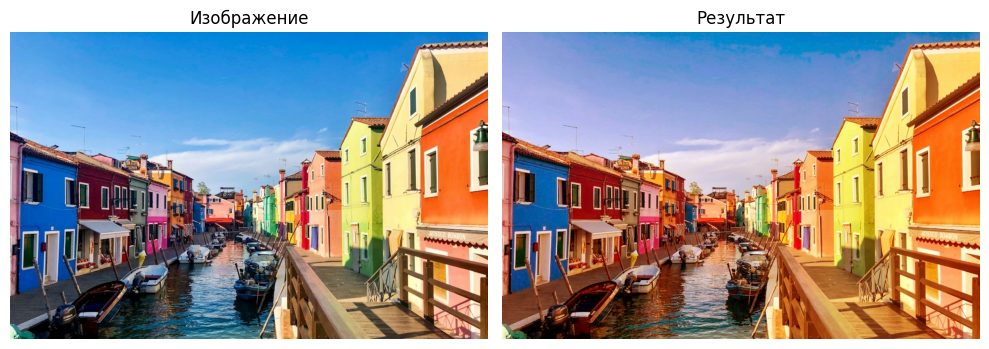

In [6]:
image = cv2.imread(str(files / 'image1.jpg'))
channels = cv2.split(image)
corrected = []
for channel, gamma in zip(channels, [1.5, 1.0, 0.5]):
    table = np.round(255 * (np.arange(256) / 255.0) ** gamma).astype(np.uint8)
    corrected.append(cv2.LUT(channel, table))
result = cv2.merge(corrected)

fig, axes = plt.subplots(1, 2, figsize=(10, 5), squeeze=False)
for ax, (title, image) in zip(axes.flat, [('Изображение', image),
        ('Результат', result)]):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis('off')
for ax in list(axes.flat)[2:]:
    ax.axis('off')
fig.tight_layout()
plt.show()
plt.close(fig)

# Тема №4. Работа с гистограммами в OpenCV

## Задание 7:  
Напишите процедуру для улучшения контрастности изображения:

- Считывает изображение в оттенках серого.
- Строит его гистограмму с использованием `cv.calcHist()`.
- Применяет эквализацию гистограммы методом `cv2.equalizeHist()`.
- Отображает на одном графике исходное и эквализованное изображения вместе с их гистограммами.

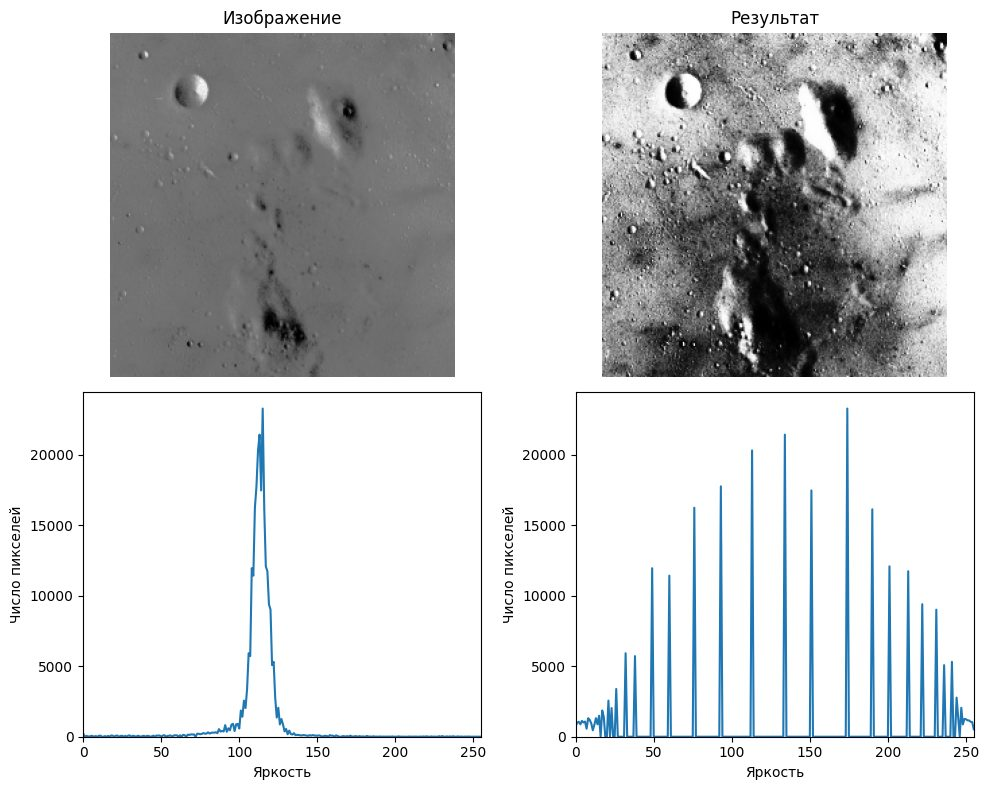

In [7]:
cv2.imwrite(str(files / 'moon.png'), data.moon())
gray = cv2.imread(str(files / 'moon.png'), cv2.IMREAD_GRAYSCALE)
result = cv2.equalizeHist(gray)
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for col, (title, image) in enumerate([('Изображение', gray), ('Результат', result)]):
    axes[0, col].imshow(image, cmap='gray', vmin=0, vmax=255)
    axes[0, col].set_title(title)
    axes[0, col].axis('off')
    hist = cv2.calcHist([image], [0], None, [256], [0, 256])
    axes[1, col].plot(hist.ravel())
    axes[1, col].set(xlim=(0, 255), xlabel='Яркость', ylabel='Число пикселей')
limit = max(ax.get_ylim()[1] for ax in axes[1])
for ax in axes[1]:
    ax.set_ylim(0, limit)
fig.tight_layout()
plt.show()
plt.close(fig)

## Задание 8:  
Используйте метод CLAHE для улучшения деталей в затемненных областях цветного изображения:

- Преобразуйте изображение из BGR в LAB цветовое пространство.
- Разделите изображение на каналы и примените `cv2.createCLAHE()` к каналу яркости L.
- Объедините обработанный канал L с исходными каналами A и B.
- Преобразуйте изображение обратно в BGR.
- Отобразите исходное и обработанное изображения для сравнения вместе с их гистограммами.

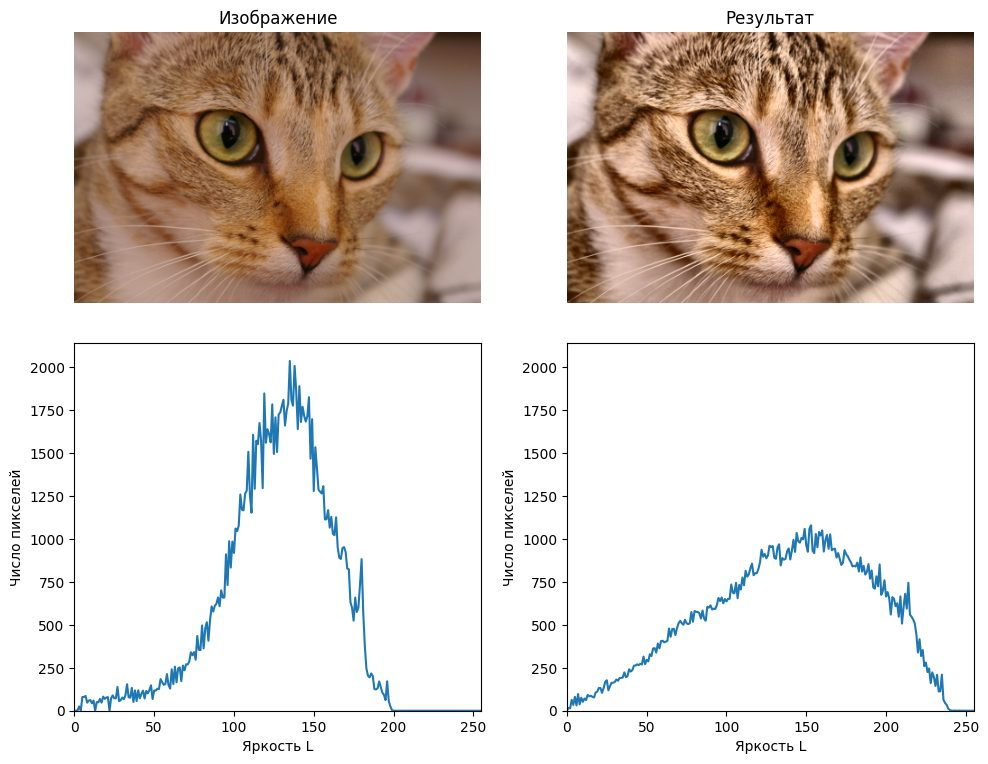

In [8]:
cv2.imwrite(str(files / 'image3.png'), cv2.cvtColor(data.chelsea(), cv2.COLOR_RGB2BGR))
original = cv2.imread(str(files / 'image3.png'))
l, a, b = cv2.split(cv2.cvtColor(original, cv2.COLOR_BGR2LAB))
l_new = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(l)
result = cv2.cvtColor(cv2.merge((l_new, a, b)), cv2.COLOR_LAB2BGR)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for col, (title, image, lightness) in enumerate([
        ('Изображение', original, l), ('Результат', result, l_new)]):
    axes[0, col].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    axes[0, col].set_title(title)
    axes[0, col].axis('off')
    hist = cv2.calcHist([lightness], [0], None, [256], [0, 256])
    axes[1, col].plot(hist.ravel())
    axes[1, col].set(xlim=(0, 255), xlabel='Яркость L', ylabel='Число пикселей')
limit = max(ax.get_ylim()[1] for ax in axes[1])
for ax in axes[1]:
    ax.set_ylim(0, limit)
fig.tight_layout()
plt.show()
plt.close(fig)

## Затем:  
Исследуйте влияние размера окна (tileGridSize) и порога по сравнению с гистограммой (clipLimit) в методе CLAHE на конечный результат. Попробуйте несколько различных значений и визуализируйте результаты.

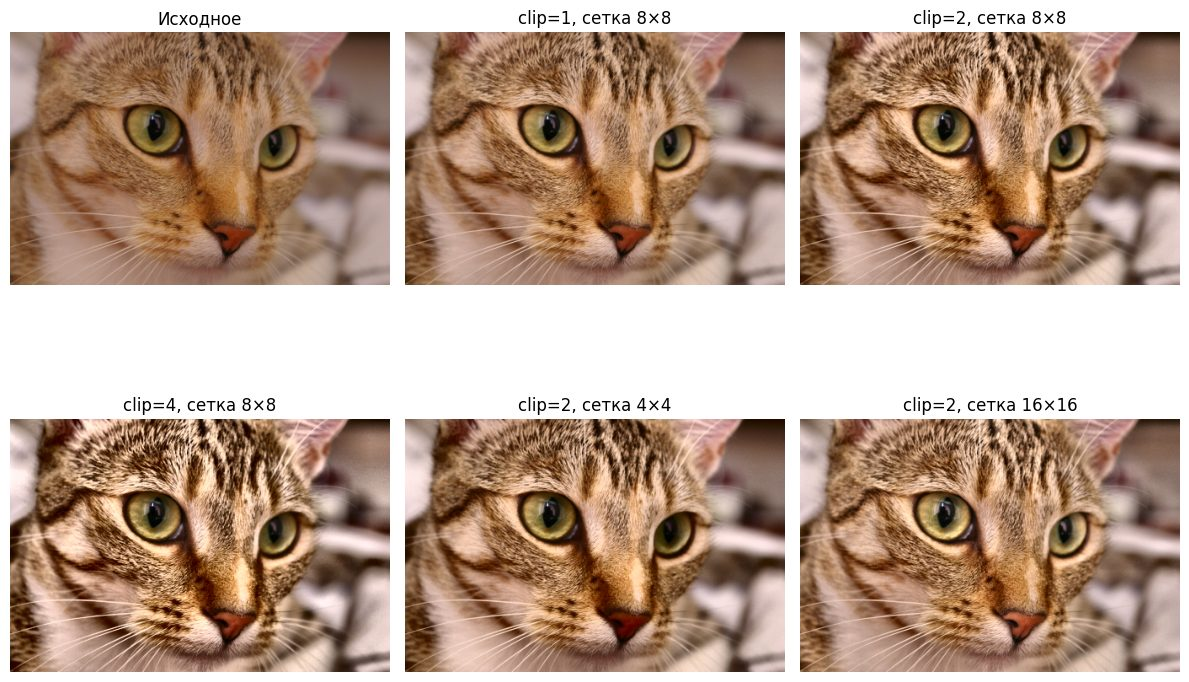

In [9]:
settings = [(1.0, (8, 8)), (2.0, (8, 8)), (4.0, (8, 8)),
            (2.0, (4, 4)), (2.0, (16, 16))]
variants = [original]
for clip, grid in settings:
    l_new = cv2.createCLAHE(clipLimit=clip, tileGridSize=grid).apply(l)
    result = cv2.cvtColor(cv2.merge((l_new, a, b)), cv2.COLOR_LAB2BGR)
    variants.append(result)

fig, axes = plt.subplots(2, 3, figsize=(12, 9))
titles = ['Исходное'] + [f'clip={clip:g}, сетка {grid[0]}×{grid[1]}' for clip, grid in settings]
for ax, title, image in zip(axes.flat, titles, variants):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis('off')
fig.tight_layout()
plt.show()
plt.close(fig)

# Комплексное задание №1. Улучшение качества отсканированного документа с использованием OpenCV

## Краткое описание задания:

- Необходимо написать функцию для улучшения качества отсканированного документа с использованием методов обработки изображений, изученных ранее. Функция должна принимать на вход изображение отсканированного документа и возвращать его улучшенную версию, готовую для дальнейшего использования, например, для распознавания текста.

Датасет с отсканированными изображениями можно найти в сети Интернет.

---

## Алгоритм действий:

#### Реализуйте функцию на языке Python с использованием библиотеки OpenCV, которая выполняет следующие этапы обработки:

### 1. Чтение, запись и отображение изображений:

- Функция должна принимать на вход изображение отсканированного документа (например, в формате JPEG или PNG)
- Проверьте наличие альфа-канала в изображении и, если он присутствует, загрузите изображение в режиме `cv2.IMREAD_UNCHANGED`, иначе используйте `cv2.IMREAD_COLOR`
- Отобразите исходное изображение для визуальной проверки

### 2. Работа с цветовыми палитрами:

- Преобразуйте изображение в оттенки серого, используя `cv2.cvtColor()` с параметром `cv2.COLOR_BGR2GRAY`.
- Отобразите полученное изображение в оттенках серого.

### 3. Слияние и усиление:

- Примените медианный фильтр (`cv2.medianBlur()`) для удаления шумов с изображения. Выберите подходящий размер ядра (например, 3 или 5). Отобразите результат.
- Используйте фильтр сглаживания с применением прямой свертки (`cv2.filter2D()`) с заданным ядром для повышения четкости. Например, можно использовать фильтр "Unsharp Masking":
  - Создайте ядро для повышения резкости. Пример ядра:
    ```python
    kernel = np.array([[-1, -1, -1],
                       [-1,  9, -1],
                       [-1, -1, -1]])
    ```
  - Примените фильтр к изображению и отобразите результат.

### 4. Работа с гистограммами:

- Примените метод CLAHE (Contrast Limited Adaptive Histogram Equalization) для улучшения контрастности изображения:
  - Создайте объект CLAHE с параметрами `clipLimit=2.0` и `tileGridSize=(8,8)`.
  - Примените CLAHE к изображению.
  - отобразите результат.
- Постройте гистограммы яркости исходного и обработанного изображений для сравнения.

---

### Требования к функции:

- Функция должна называться: `improve_scan(image)`, где `image` — входное изображение в виде массива NumPy.
- Функция должна возвращать улучшенное изображение в виде массива NumPy.
- В ходе работы функция должна опционально отображать промежуточные результаты для наглядности (в условиях Colab использовать соответствующие методы вывода изображений). Для этого следует ввести отдельный параметр (например: `visible=True`) и реализовать с ним соответствующую логику.

---

### Дополнительные требования:

- Обработка ошибок:
  - Убедитесь, что функция корректно обрабатывает ситуации, когда на вход подается некорректное изображение.
  - Добавьте проверки на тип входных данных.

- Документация и комментарии:
  - Функция должна быть снабжена понятной документацией: опишите, какие преобраования выполняются и для чего.
  - Добавьте комментарии к основным участкам кода для пояснения выполняемых действий.

---

### Подсказки и рекомендации:

- Медианный фильтр:
  Функция `cv2.medianBlur(src, ksize)` принимает на вход изображение и размер ядра (должен быть нечетным числом).

- CLAHE:
  - Создайте объект CLAHE с помощью `cv2.createCLAHE(clipLimit, tileGridSize)`.
  - Примените метод `apply()` к изображению в оттенках серого.

- Отображение изображений в Google Colab:
  - Используйте `matplotlib.pyplot` для отображения изображений.
  - Помните, что `cv2.imread()` загружает изображения в формате BGR, поэтому для корректного отображения в Matplotlib Преобразуйте изображение в RGB с помощью `cv2.cvtColor(image, cv2.COLOR_BGR2RGB)`.

---

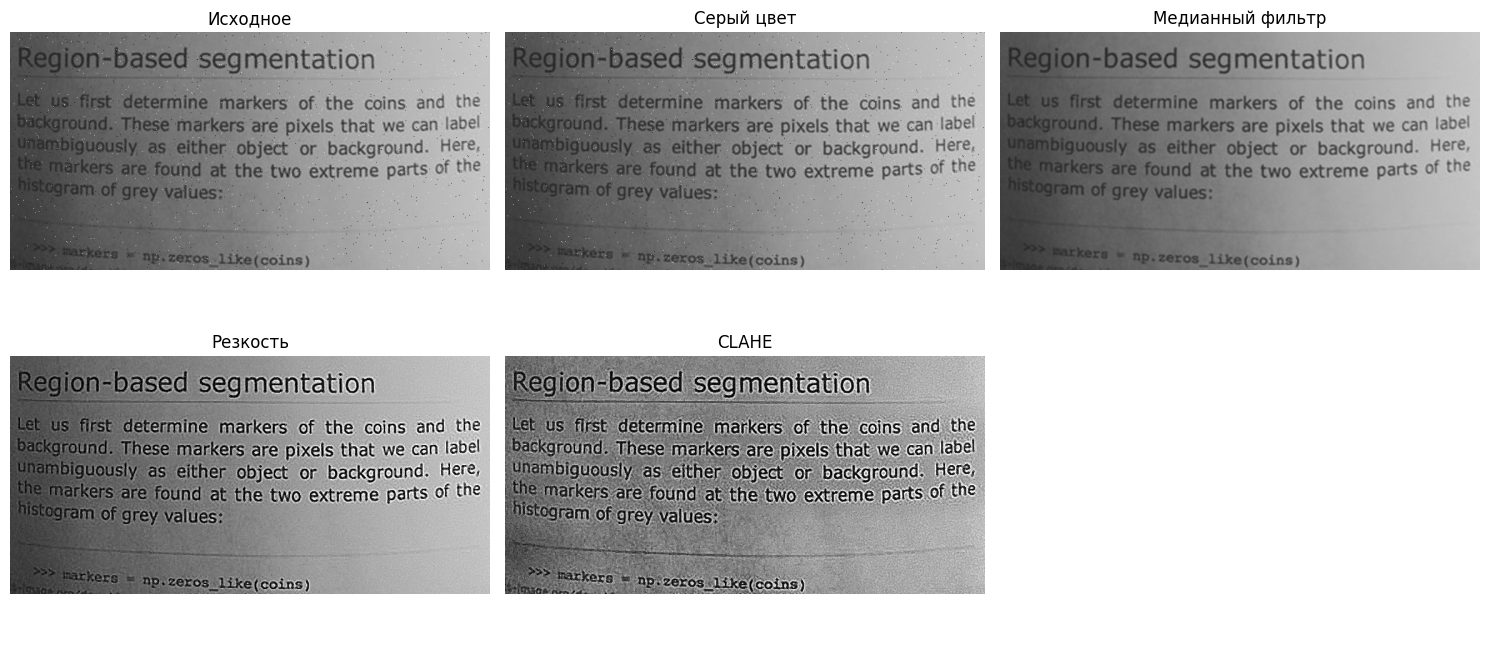

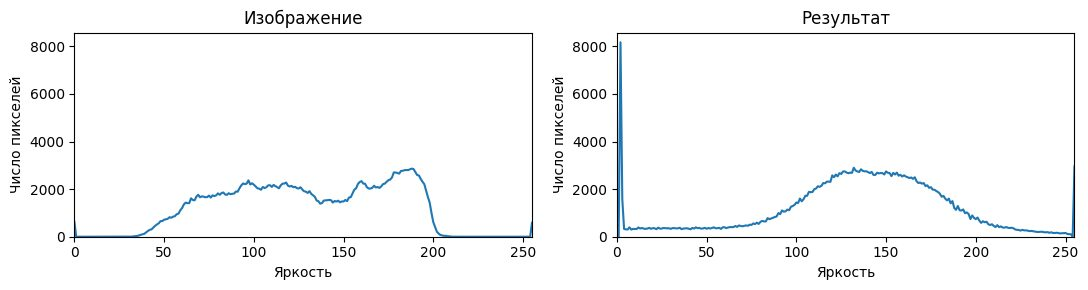

In [10]:
def improve_scan(image, median_kernel_size=3, sharp_kernel=None,
                 clahe_clip=2.0, clahe_grid=(8, 8), visible=True):
    """Убрать мелкий шум, повысить резкость и локальный контраст скана.

    image: uint8-массив в сером цвете, BGR или BGRA; исходный массив не меняется.
    Возвращает двумерный uint8-массив. visible включает вывод этапов и гистограмм.
    """
    if not isinstance(image, np.ndarray):
        raise TypeError('image должен быть массивом NumPy')
    if image.size == 0:
        raise ValueError('Изображение пустое')
    if image.dtype != np.uint8:
        raise TypeError('Ожидается изображение uint8 в диапазоне 0–255')
    if image.ndim not in (2, 3) or (image.ndim == 3 and image.shape[2] not in (1, 3, 4)):
        raise ValueError('Нужно серое изображение либо 3 или 4 канала')
    if not isinstance(median_kernel_size, (int, np.integer)) or median_kernel_size not in (3, 5):
        raise ValueError('Размер медианного фильтра должен быть 3 или 5')
    if not np.isfinite(clahe_clip) or clahe_clip <= 0:
        raise ValueError('clahe_clip должен быть положительным')
    if len(clahe_grid) != 2 or any(not isinstance(x, (int, np.integer)) or x <= 0 for x in clahe_grid):
        raise ValueError('clahe_grid должен содержать два положительных целых числа')

    # Альфа-канал накладываем на белый фон, затем переводим в серый цвет.
    if image.ndim == 2:
        gray = image.copy()
    elif image.shape[2] == 1:
        gray = image[:, :, 0].copy()
    elif image.shape[2] == 4:
        alpha = image[:, :, 3:4].astype(np.float32) / 255
        bgr = np.round(image[:, :, :3] * alpha + 255 * (1 - alpha)).astype(np.uint8)
        gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    else:
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    if sharp_kernel is None:
        sharp_kernel = [[0, -0.25, 0], [-0.25, 2, -0.25], [0, -0.25, 0]]
    kernel = np.asarray(sharp_kernel, dtype=np.float32)
    if (kernel.ndim != 2 or not kernel.size or any(s % 2 == 0 for s in kernel.shape)
            or not np.isfinite(kernel).all()):
        raise ValueError('Ядро должно быть конечной матрицей с нечётными размерами')

    # Убираем точечный шум и повышаем резкость текста.
    median = cv2.medianBlur(gray, median_kernel_size)
    sharp = cv2.filter2D(median, cv2.CV_32F, kernel, borderType=cv2.BORDER_REFLECT_101)
    sharp = np.clip(np.round(sharp), 0, 255).astype(np.uint8)
    # Локально выравниваем контраст после фильтрации.
    result = cv2.createCLAHE(clipLimit=float(clahe_clip), tileGridSize=tuple(clahe_grid)).apply(sharp)

    if visible:
        stages = [gray, median, sharp, result]
        fig, axes = plt.subplots(2, 3, figsize=(15, 7))
        if image.ndim == 3 and image.shape[2] in (3, 4):
            conversion = cv2.COLOR_BGRA2RGBA if image.shape[2] == 4 else cv2.COLOR_BGR2RGB
            original = cv2.cvtColor(image, conversion)
        else:
            original = image.reshape(image.shape[:2])
        titles = ['Исходное', 'Серый цвет', 'Медианный фильтр', 'Резкость', 'CLAHE']
        for ax, title, stage in zip(axes.flat, titles, [original] + stages):
            ax.imshow(stage, cmap='gray', vmin=0, vmax=255)
            ax.set_title(title)
            ax.axis('off')
        axes.flat[-1].axis('off')
        fig.tight_layout()
        plt.show()
        plt.close(fig)
        fig, axes = plt.subplots(1, 2, figsize=(11, 3))
        for ax, title, values in zip(axes, ['Изображение', 'Результат'], [gray, result]):
            ax.plot(cv2.calcHist([values], [0], None, [256], [0, 256]).ravel())
            ax.set(title=title, xlim=(0, 255), xlabel='Яркость', ylabel='Число пикселей')
        limit = max(ax.get_ylim()[1] for ax in axes)
        for ax in axes:
            ax.set_ylim(0, limit)
        fig.tight_layout()
        plt.show()
        plt.close(fig)
    return result

from skimage import data

page = cv2.resize(data.page(), None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
rng = np.random.default_rng(17)
shadow = np.linspace(0.58, 0.92, page.shape[1])[None, :]
scan_gray = np.clip((page.astype(np.float32) * 0.7 + 50) * shadow
                    + rng.normal(0, 2, page.shape), 0, 255).astype(np.uint8)
impulse = rng.random(page.shape)
scan_gray[impulse < 0.002] = 0
scan_gray[impulse > 0.998] = 255
scan_path = files / 'scan.png'
cv2.imwrite(str(scan_path), scan_gray)
raw = cv2.imread(str(scan_path), cv2.IMREAD_UNCHANGED)
image = raw if raw.ndim == 3 and raw.shape[2] == 4 else cv2.imread(str(scan_path), cv2.IMREAD_COLOR)
strong_kernel = np.array([[-1, -1, -1], [-1, 9, -1], [-1, -1, -1]], dtype=np.float32)
improved = improve_scan(image, sharp_kernel=strong_kernel)

## Дополнительное задание:

- Поэкспериментируйте с параметрами медианного фильтра, ядром для фильтра повышения резкости и параметрами CLAHE для достижения наилучшего результата.
- Добавьте возможность передачи этих параметров в функцию `improve_scan` для более гибкой настройки обработки. В качестве параметров по умолчанию установите те, которые показали себя лучше всего по результатам экспериментов

Пример с параметрами:

```python
def improve_scan(image,
                 median_kernel_size=3,
                 sharp_kernel= np.array([[-1, -1, -1],
                                         [-1,  9, -1],
                                         [-1, -1, -1]]),
                 clahe_clip=2.0,
                 clahe_grid=(8,8),
                 visible=True):
    # Реализация с учетом переданных параметров
    ...
```

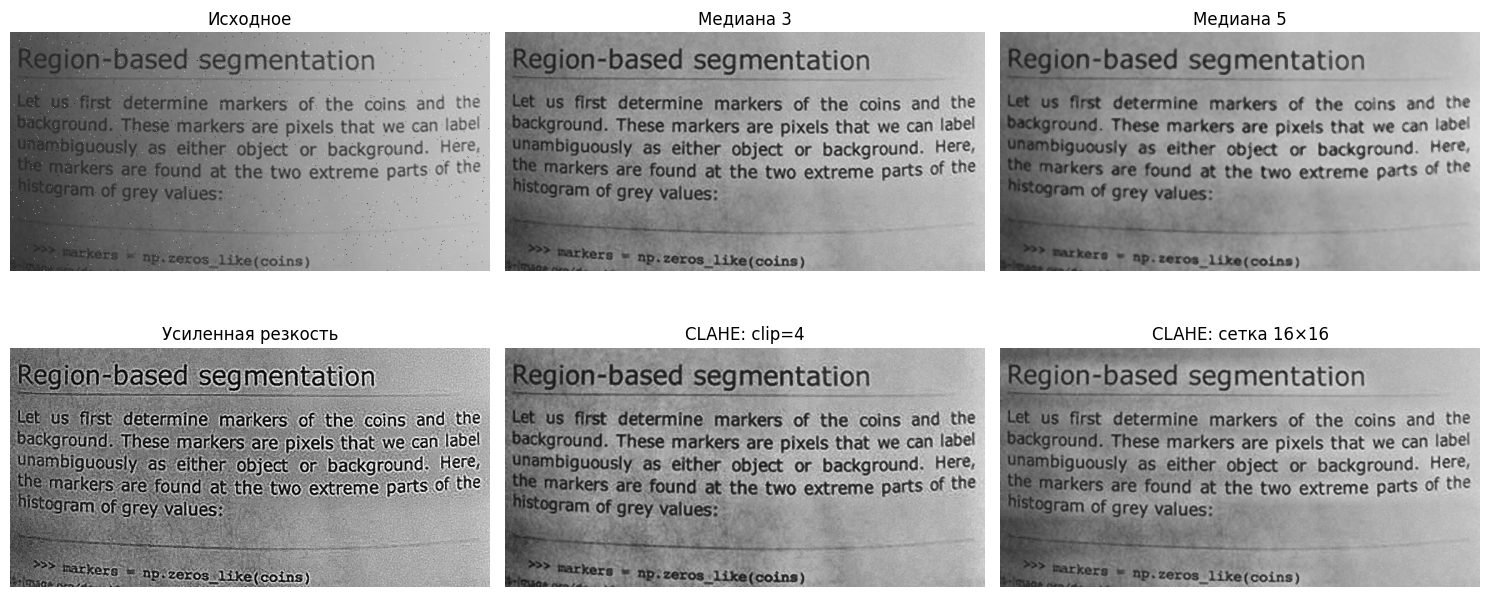

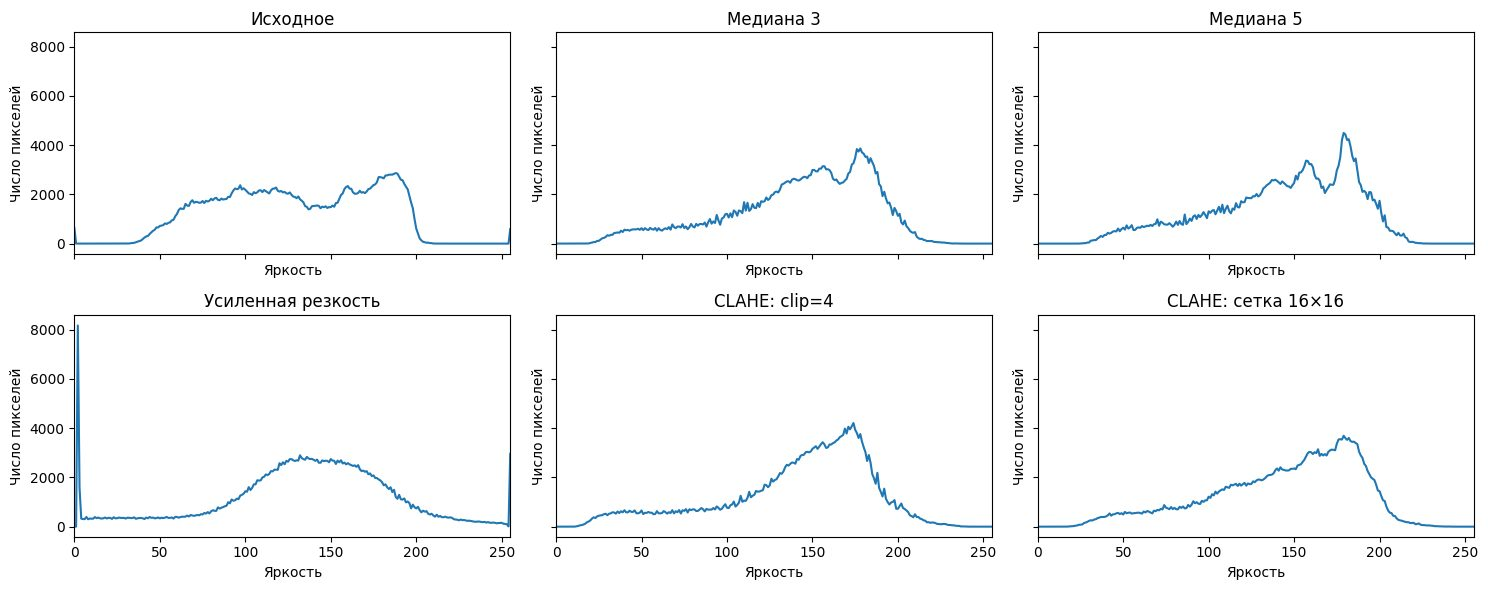

In [11]:
settings = [
    {},
    {'median_kernel_size': 5},
    {'sharp_kernel': strong_kernel},
    {'clahe_clip': 4.0},
    {'clahe_grid': (16, 16)},
]
variants = [cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)]
for options in settings:
    variants.append(improve_scan(image, visible=False, **options))

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
titles = ['Исходное', 'Медиана 3', 'Медиана 5', 'Усиленная резкость',
          'CLAHE: clip=4', 'CLAHE: сетка 16×16']
for ax, title, result in zip(axes.flat, titles, variants):
    ax.imshow(result, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')
fig.tight_layout()
plt.show()
plt.close(fig)

fig, axes = plt.subplots(2, 3, figsize=(15, 6), sharex=True, sharey=True)
for ax, title, result in zip(axes.flat, titles, variants):
    hist = cv2.calcHist([result], [0], None, [256], [0, 256])
    ax.plot(hist.ravel())
    ax.set(title=title, xlim=(0, 255), xlabel='Яркость', ylabel='Число пикселей')
fig.tight_layout()
plt.show()
plt.close(fig)
